<a href="https://colab.research.google.com/github/Hadeel-93/HW-5/blob/main/HW_5_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import time, math, numpy as np, pandas as pd
import torch, torch.nn as nn, torch.optim as optim
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
# Load the full housing dataset
df = pd.read_csv(
    "/content/drive/My Drive/Introduction to Machine Learning/Housing.csv"
)

# Target variable
y_full = df["price"].astype(float).values

# Use ALL input features (exclude only the target price)
X_df = df.drop(columns=["price"]).copy()

# Convert binary categorical variables to 0 and 1
binary_cols = [
    "mainroad", "guestroom", "basement",
    "hotwaterheating", "airconditioning", "prefarea"
]

for col in binary_cols:
    X_df[col] = X_df[col].map({"yes": 1, "no": 0})

# Convert furnishingstatus into numerical dummy variables
X_df = pd.get_dummies(
    X_df,
    columns=["furnishingstatus"],
    drop_first=True,
    dtype=int
)

feature_names = X_df.columns.tolist()

print("Input features:", feature_names)
print("Number of input parameters:", len(feature_names))
print("Dataset shape:", X_df.shape)

Input features: ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']
Number of input parameters: 13
Dataset shape: (545, 13)


In [3]:
dtype = torch.float64

X_full = torch.tensor(
    X_df.astype(float).values,
    dtype=dtype
)

y_full = torch.tensor(
    y_full, dtype=dtype
).view(-1, 1)

# 80% training / 20% validation
N = X_full.shape[0]
n_train = int(0.8 * N)

g = torch.Generator().manual_seed(42)
perm = torch.randperm(N, generator=g)

idx_tr = perm[:n_train]
idx_va = perm[n_train:]

X_train_raw = X_full[idx_tr]
y_train_raw = y_full[idx_tr]

X_val_raw = X_full[idx_va]
y_val_raw = y_full[idx_va]

# Standardize input features using training data only
mu_X = X_train_raw.mean(dim=0)
sd_X = X_train_raw.std(dim=0) + 1e-8

Xt = (X_train_raw - mu_X) / sd_X
Xv = (X_val_raw - mu_X) / sd_X

# Standardize target prices too, for stable gradient descent
mu_y = y_train_raw.mean()
sd_y = y_train_raw.std() + 1e-8

yt = (y_train_raw - mu_y) / sd_y
yv = (y_val_raw - mu_y) / sd_y

# Keep actual prices for final evaluation
y_train = y_train_raw.numpy().flatten()
y_val = y_val_raw.numpy().flatten()

In [4]:
EPOCHS       = 5000
LRS          = [0.1, 0.01, 0.001, 0.0001]
DENSE_LOG    = 1          # log every epoch (for smooth curves)
REPORT_STEP  = 500        # print every 500 epochs (per instruction)
USE_MOMENTUM = True

torch.manual_seed(0) #reproducibility
dtype = torch.float64

df = pd.read_csv("/content/drive/My Drive/Introduction to Machine Learning/Housing.csv")
cols = ["area", "bedrooms", "bathrooms", "stories", "parking", "price"]
df = df[cols].copy()

In [11]:
# Standardization

mu_X_t = X_train_raw.mean(dim=0)
sd_X_t = X_train_raw.std(dim=0) + 1e-8
Xt = (X_train_raw - mu_X_t) / sd_X_t
Xv = (X_val_raw   - mu_X_t) / sd_X_t

yt = y_train_raw.to(dtype)
yv = y_val_raw.to(dtype)

class LinReg(torch.nn.Module):
    def __init__(self, d):
        super().__init__()
        self.w = torch.nn.Parameter(torch.zeros(d, 1, dtype=dtype))
        self.b = torch.nn.Parameter(torch.zeros(1, dtype=dtype))
    def forward(self, X):
        return X @ self.w + self.b

def mse(yhat, y):
    return torch.mean((yhat - y) ** 2)

def train_once(lr, epochs=EPOCHS, log_every=DENSE_LOG):

    torch.manual_seed(0)
    model = LinReg(Xt.shape[1])
    if USE_MOMENTUM:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr)

    history = []
    for ep in range(epochs + 1):
        yhat = model(Xt)
        loss = mse(yhat, yt)
        opt.zero_grad(); loss.backward(); opt.step()

        if ep % log_every == 0:
            with torch.no_grad():
                tr = float(loss.item())
                vl = float(mse(model(Xv), yv).item())
            history.append((ep, tr, vl))

    with torch.no_grad():
        # Predictions on standardized price scale
        tr_pred_scaled = model(Xt)
        va_pred_scaled = model(Xv)

        # Convert predictions back to original price scale
        tr_pred = (tr_pred_scaled * sd_y + mu_y).numpy().flatten()
        va_pred = (va_pred_scaled * sd_y + mu_y).numpy().flatten()

    tr_mse = float(np.mean((tr_pred - y_train) ** 2))
    va_mse = float(np.mean((va_pred - y_val) ** 2))

    return {
        "tr_mse": tr_mse,
        "va_mse": va_mse,
        "history": history,
        "w_scaled": model.w.detach().cpu().numpy().flatten(),
        "b_scaled": float(model.b.item()),
        "val_pred": va_pred
    }

In [9]:
runs = {lr: train_once(lr=lr) for lr in LRS}
# Pick best by validation MSE
best_lr = min(LRS, key=lambda a: runs[a]["va_mse"])
best = runs[best_lr]


In [12]:
print("Best learning rate:", best_lr)
print("\nModel weights (standardized feature scale):")

for name, weight in zip(feature_names, best["w_scaled"]):
    print(f"{name}: {weight:.6f}")

print(f"Bias (standardized price scale): {best['b_scaled']:.6f}")

Best learning rate: 0.0001

Model weights (standardized feature scale):
area: 559813.395128
bedrooms: 32756.356435
bathrooms: 495869.684825
stories: 421684.088026
mainroad: 114082.714081
guestroom: 95982.895507
basement: 176181.129137
hotwaterheating: 127589.115622
airconditioning: 376966.680110
parking: 255382.175591
prefarea: 312265.740883
furnishingstatus_semi-furnished: -58283.453272
furnishingstatus_unfurnished: -240438.473107
Bias (standardized price scale): 4758646.359436


In [13]:
print("\nTrain/Validation MSE every 500 epochs")
epochs_logged = list(range(0, EPOCHS + 1, REPORT_STEP))
for lr in LRS:
    print(f"\nLR = {lr}")
    hist = {ep: (tr, vl) for (ep, tr, vl) in runs[lr]["history"]}
    for ep in epochs_logged:
        tr, vl = hist.get(ep, (float('nan'), float('nan')))
        print(f"  epoch {ep:4d}  train_MSE={tr:.6f}   val_MSE={vl:.6f}")



Train/Validation MSE every 500 epochs

LR = 0.1
  epoch    0  train_MSE=26305958620363.761719   val_MSE=16032107873289.263672
  epoch  500  train_MSE=1169256690580.322266   val_MSE=926719578549.528076
  epoch 1000  train_MSE=1169256690580.322510   val_MSE=926719578549.880005
  epoch 1500  train_MSE=1169256690580.322510   val_MSE=926719578549.879883
  epoch 2000  train_MSE=1169256690580.322510   val_MSE=926719578549.879883
  epoch 2500  train_MSE=1169256690580.322510   val_MSE=926719578549.880005
  epoch 3000  train_MSE=1169256690580.322510   val_MSE=926719578549.879883
  epoch 3500  train_MSE=1169256690580.322510   val_MSE=926719578549.879883
  epoch 4000  train_MSE=1169256690580.322510   val_MSE=926719578549.879883
  epoch 4500  train_MSE=1169256690580.322510   val_MSE=926719578549.880005
  epoch 5000  train_MSE=1169256690580.322510   val_MSE=926719578549.880005

LR = 0.01
  epoch    0  train_MSE=26305958620363.761719   val_MSE=24733857236493.062500
  epoch  500  train_MSE=1169256690

In [14]:
mse_tr  = best['tr_mse']
mse_val = best['va_mse']
rmse_tr  = math.sqrt(mse_tr)
rmse_val = math.sqrt(mse_val)

print("\nFinal metrics")
print(f"Training loss: MSE = {mse_tr:,.0f}   RMSE = {rmse_tr:,.0f}")
print(f"Validation loss  : MSE = {mse_val:,.0f}   RMSE = {rmse_val:,.0f}")



Final metrics
Training loss: MSE = 1,169,266,889,920   RMSE = 1,081,326
Validation loss  : MSE = 924,826,079,819   RMSE = 961,679


In [17]:
weights = best["w_scaled"]
B = best["b_scaled"]

print("\nBest linear model:")
print("Price = " + " + ".join([f"W_{i+1}*X_{i+1}" for i in range(len(feature_names))]) + " + B")

for i, (name, weight) in enumerate(zip(feature_names, weights)):
    print(f"  W_{i+1:<2d} ({name:<32s}) = {weight:.6f}")

print(f"  B   (Bias/Intercept)                 = {B:.6f}")


Best linear model:
Price = W_1*X_1 + W_2*X_2 + W_3*X_3 + W_4*X_4 + W_5*X_5 + W_6*X_6 + W_7*X_7 + W_8*X_8 + W_9*X_9 + W_10*X_10 + W_11*X_11 + W_12*X_12 + W_13*X_13 + B
  W_1  (area                            ) = 559813.395128
  W_2  (bedrooms                        ) = 32756.356435
  W_3  (bathrooms                       ) = 495869.684825
  W_4  (stories                         ) = 421684.088026
  W_5  (mainroad                        ) = 114082.714081
  W_6  (guestroom                       ) = 95982.895507
  W_7  (basement                        ) = 176181.129137
  W_8  (hotwaterheating                 ) = 127589.115622
  W_9  (airconditioning                 ) = 376966.680110
  W_10 (parking                         ) = 255382.175591
  W_11 (prefarea                        ) = 312265.740883
  W_12 (furnishingstatus_semi-furnished ) = -58283.453272
  W_13 (furnishingstatus_unfurnished    ) = -240438.473107
  B   (Bias/Intercept)                 = 4758646.359436


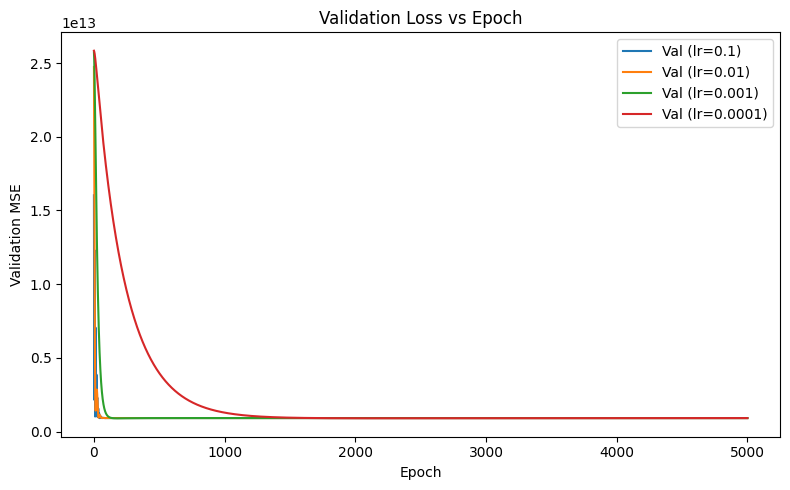

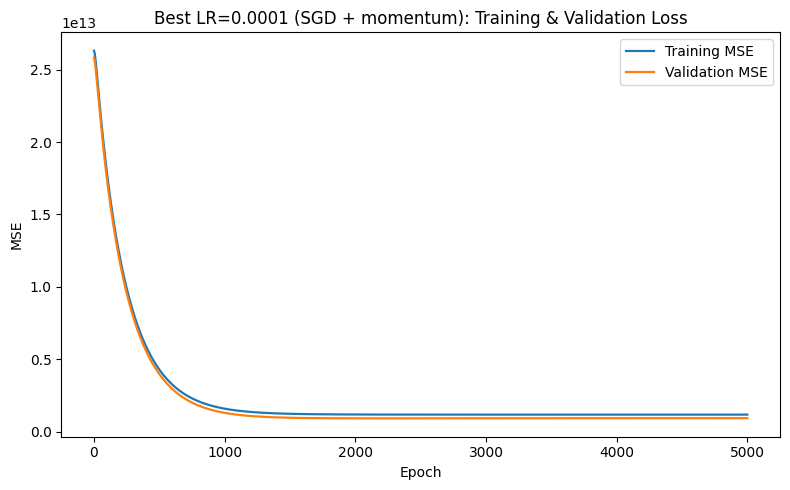

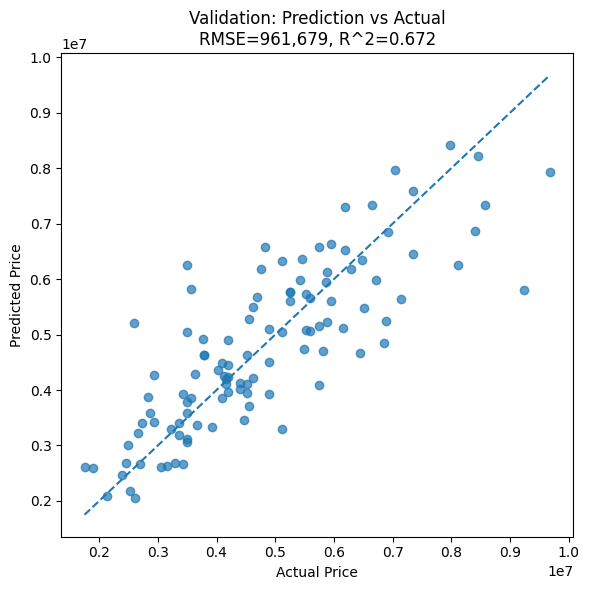

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

def _smooth(arr, k=21):
    if k <= 1 or k > len(arr): return arr
    w = np.ones(k) / k
    return np.convolve(arr, w, mode="same")

# Validation loss vs Epoch (all LRs)
plt.figure(figsize=(8,5))
for lr in LRS:
    hist = runs[lr]["history"]
    ep = np.array([h[0] for h in hist])
    vl = np.array([h[2] for h in hist])
    plt.plot(ep, vl, linewidth=1.5, label=f"Val (lr={lr})")
plt.xlabel("Epoch"); plt.ylabel("Validation MSE")
plt.title("Validation Loss vs Epoch")
plt.legend(); plt.tight_layout(); plt.show()

# Best LR – Train & Val loss vs Epoch
hist = best["history"]
ep = np.array([h[0] for h in hist])
tr = np.array([h[1] for h in hist])
vl = np.array([h[2] for h in hist])


plt.figure(figsize=(8,5))
plt.plot(ep, tr, linewidth=1.6, label="Training MSE")
plt.plot(ep, vl, linewidth=1.6, label="Validation MSE")
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.title(f"Best LR={best_lr} (SGD{' + momentum' if USE_MOMENTUM else ''}): Training & Validation Loss")
plt.legend(); plt.tight_layout(); plt.show()

# Prediction vs Actual (Validation)
y_val_pred = best["val_pred"]
rmse_val = math.sqrt(mean_squared_error(y_val, y_val_pred))
r2_val   = r2_score(y_val, y_val_pred)

plt.figure(figsize=(6,6))
plt.scatter(y_val, y_val_pred, alpha=0.7)
mn = min(y_val.min(), y_val_pred.min()); mx = max(y_val.max(), y_val_pred.max())
plt.plot([mn, mx], [mn, mx], linestyle='--')
plt.xlabel("Actual Price"); plt.ylabel("Predicted Price")
plt.title(f"Validation: Prediction vs Actual\nRMSE={rmse_val:,.0f}, R^2={r2_val:.3f}")
plt.tight_layout(); plt.show()